# SRCNN variants (h5 patches version)
Training patches come from the ready-made `amiraliabedi97/div2k-patch` dataset (h5 files), so no patching is done here.

**In Kaggle: Add Input -> `amiraliabedi97/div2k-patch`** (mounted, nothing is downloaded). If it is not attached, only the one needed h5 file is downloaded.

Also: no `tqdm.auto` widgets, no `DataParallel`, all data on the GPU, text progress log.

In [1]:
import kagglehub
# validation (Set14) and test (Set5) images; the patch dataset is found later by find_h5()
BENCH = kagglehub.dataset_download("jesucristo/super-resolution-benchmarks")
print(BENCH)

/kaggle/input/datasets/jesucristo/super-resolution-benchmarks


In [2]:
import os, json, glob, time, random, gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| GPUs:", torch.cuda.device_count())

def pretty(df, caption=None):
    sty = df.style.set_table_styles([
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold; padding: 6px 0;"},
        {"selector": "th", "props": "text-align: center; padding: 6px 14px;"},
        {"selector": "td", "props": "text-align: center; padding: 6px 14px;"},
        {"selector": "th.row_heading", "props": "text-align: left;"},
        {"selector": "thead th", "props": "border-bottom: 2px solid #888;"},
    ])
    return sty.set_caption(caption) if caption else sty

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device: cuda | GPUs: 2


In [3]:
VAL_DIR   = f"{BENCH}/Set14/Set14/original"
TEST_DIR  = f"{BENCH}/Set5/Set5/original"
# full-image test sets (every image is reconstructed whole, PSNR per image, then averaged)
TEST_SETS = {"Set5": TEST_DIR, "Set14": VAL_DIR}

# training patches: <patch size>/seed<H5_SEED>.h5 inside the div2k-patch dataset
# (available patch sizes: 12, 24, 36, 48, 60, 72, 84, 96, 108, 120 -> 100000 patches each)
H5_REPO = "amiraliabedi97/div2k-patch"
H5_SEED = 42   # which file to use: 42 ... 46 (same file for every model, so the comparison is fair)

SCALES = [2, 3, 4]
SEEDS = [42, 43, 44, 45, 46]
e = 2000
EPOCHS = {"baseline": e, "4layer": e}
LR_MAX, LR_MIN = 1e-3, 1e-7
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 128
N_TRAIN, N_VAL = 1000, 100
PATCH = {2: 72, 3: 72, 4: 72}
DATA_SEED = 0
DEBUG = False

if DEBUG:
    SCALES, SEEDS, N_TRAIN, N_VAL = [2], [42], 512, 64
    EPOCHS = {k: 2 for k in EPOCHS}

OUT_DIR = "/kaggle/working/" + ("debug" if DEBUG else "checkpoints_lr1e-3")
os.makedirs(OUT_DIR, exist_ok=True)
criterion = nn.MSELoss()

In [4]:
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")

def list_images(folder, min_size=0):
    assert folder and os.path.isdir(folder), f"folder not found: '{folder}'"
    files = sorted(os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))
    files = [f for f in files if min(Image.open(f).size) >= min_size]
    assert files, f"no usable images in {folder}"
    return files

def extract_patches(folder, n_patches, size, seed):
    files = list_images(folder, min_size=size)
    rng = np.random.default_rng(seed)
    out = np.empty((n_patches, size, size), np.uint8)
    counts = np.full(len(files), n_patches // len(files))
    counts[rng.choice(len(files), n_patches % len(files), replace=False)] += 1
    k = 0
    for f, c in zip(files, counts):
        if c == 0:
            continue
        y = np.array(Image.open(f).convert("YCbCr").split()[0])
        H, W = y.shape
        for yy, xx in zip(rng.integers(0, H - size + 1, c), rng.integers(0, W - size + 1, c)):
            out[k] = y[yy:yy + size, xx:xx + size]
            k += 1
    return out

def make_lr(hr, scale):
    n, p, _ = hr.shape
    lr = np.empty_like(hr)
    for i in range(n):
        im = Image.fromarray(hr[i])
        lr[i] = np.array(im.resize((p // scale, p // scale), Image.BICUBIC).resize((p, p), Image.BICUBIC))
    return lr

import h5py

def find_h5(patch, file_seed=H5_SEED):
    rel = f"{patch}/seed{file_seed}.h5"
    hits = glob.glob(f"/kaggle/input/**/div2k-patch/{rel}", recursive=True)
    if hits:
        return hits[0]
    print(f"{rel} is not mounted, downloading only this file ...", flush=True)
    return kagglehub.dataset_download(H5_REPO, path=rel)

def load_h5_patches(patch, n, seed, file_seed=H5_SEED):
    """n random HR patches (uint8, Y channel) from the ready-made h5 file -> [n, patch, patch]."""
    path = find_h5(patch, file_seed)
    with h5py.File(path, "r") as f:
        keys = [k for k in f.keys() if isinstance(f[k], h5py.Dataset) and f[k].ndim >= 3]
        assert keys, f"no image dataset in {path}, found: {list(f.keys())}"
        ds = f[keys[0]]
        print(f"{os.path.basename(path)}: key '{keys[0]}', shape {ds.shape}, dtype {ds.dtype}", flush=True)
        total = ds.shape[0]
        if n >= total:
            arr = ds[:]
        else:
            idx = np.sort(np.random.default_rng(seed).choice(total, n, replace=False))
            arr = ds[idx]
    if arr.ndim == 4:                      # [N,H,W,1] / [N,1,H,W] / [N,H,W,3]
        if arr.shape[-1] == 1:
            arr = arr[..., 0]
        elif arr.shape[1] == 1:
            arr = arr[:, 0]
        elif arr.shape[-1] == 3:
            arr = np.rint(arr.astype(np.float64) @ np.array([0.299, 0.587, 0.114]))
    if arr.dtype != np.uint8:              # float patches -> uint8
        arr = arr * 255.0 if arr.max() <= 1.0 else arr
        arr = np.clip(np.rint(arr), 0, 255).astype(np.uint8)
    assert arr.shape[1:] == (patch, patch), f"unexpected patch shape {arr.shape}"
    return np.ascontiguousarray(arr)

def build_data(scale):
    p = PATCH[scale]
    assert p % scale == 0
    tr = load_h5_patches(p, N_TRAIN, DATA_SEED)
    va = extract_patches(VAL_DIR, N_VAL, p, DATA_SEED + 1)
    return {"train_x": torch.from_numpy(make_lr(tr, scale)), "train_y": torch.from_numpy(tr),
            "val_x": torch.from_numpy(make_lr(va, scale)), "val_y": torch.from_numpy(va)}

In [5]:
class SRCNN(nn.Module):
    def __init__(self, kernels, filters):
        super().__init__()
        assert len(kernels) == len(filters) + 1
        layers, c_in = [], 1
        for i, (k, c_out) in enumerate(zip(kernels, list(filters) + [1])):
            layers.append(nn.Conv2d(c_in, c_out, k, padding=k // 2))
            if i < len(kernels) - 1:
                layers.append(nn.ReLU(inplace=True))
            c_in = c_out
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

MODELS = {
    "baseline": ([9, 1, 5],    [64, 32]),
    "4layer":   ([9, 3, 1, 5], [32, 16, 16]),
}

def build_model(name):
    return SRCNN(*MODELS[name])

rows = [{"Model": n, "Kernels": " - ".join(map(str, k)), "Filters": " - ".join(map(str, f)),
         "Parameters": sum(p.numel() for p in build_model(n).parameters())} for n, (k, f) in MODELS.items()]
display(pretty(pd.DataFrame(rows).set_index("Model"), "Model sizes"))

,Kernels,Filters,Parameters
Model,,,
baseline,9 - 1 - 5,64 - 32,8129
4layer,9 - 3 - 1 - 5,32 - 16 - 16,7921


In [6]:
def run_dir(scale, seed):
    return os.path.join(OUT_DIR, f"scale{scale}x", f"seed{seed}")

def summary_path(scale, seed, name):
    return os.path.join(run_dir(scale, seed), f"{name}_summary.json")

def save_weights(model, path):
    torch.save({k: v.cpu() for k, v in model.state_dict().items()}, path)

def prep(u8):
    return (u8.float() / 255.0).unsqueeze(1)

def train_run(name, scale, seed, data):
    n_epochs = EPOCHS[name]
    d = run_dir(scale, seed)
    os.makedirs(d, exist_ok=True)

    set_seed(seed)
    model = build_model(name).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())

    # all data on the GPU once (it is tiny)
    tx, ty = data["train_x"].to(DEVICE), data["train_y"].to(DEVICE)
    vx, vy = data["val_x"].to(DEVICE), data["val_y"].to(DEVICE)

    opt = torch.optim.Adam(model.parameters(), lr=LR_MAX, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs, eta_min=LR_MIN)
    gen = torch.Generator().manual_seed(seed)
    n = len(tx)

    @torch.no_grad()
    def validate_gpu():
        model.eval()
        out = model(prep(vx)).clamp(0, 1)
        mse = ((out - prep(vy)) ** 2).mean(dim=(1, 2, 3))
        psnr = 10 * torch.log10(1.0 / mse.clamp_min(1e-10))
        return mse.mean().item(), psnr.mean().item()

    history, best = [], {"psnr": -1.0, "epoch": 0}
    t0 = time.time()
    for epoch in range(1, n_epochs + 1):
        model.train()
        lr_now = opt.param_groups[0]["lr"]
        total = torch.zeros((), device=DEVICE)
        for idx in torch.randperm(n, generator=gen).split(BATCH_SIZE):
            idx = idx.to(DEVICE)
            loss = criterion(model(prep(tx[idx])), prep(ty[idx]))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        sched.step()

        val_loss, val_psnr = validate_gpu()
        history.append({"epoch": epoch, "lr": lr_now, "train_loss": (total / n).item(),
                        "val_loss": val_loss, "val_psnr": val_psnr})
        if val_psnr > best["psnr"]:
            best = {"psnr": val_psnr, "epoch": epoch}
            save_weights(model, os.path.join(d, f"{name}_best.pth"))
        if epoch % 100 == 0:
            print(f"    epoch {epoch}/{n_epochs}  val_psnr {val_psnr:.3f}", flush=True)

    save_weights(model, os.path.join(d, f"{name}_last.pth"))
    pd.DataFrame(history).to_csv(os.path.join(d, f"{name}_history.csv"), index=False)

    summary = {"scale": scale, "seed": seed, "model": name, "params": n_params,
               "best_psnr": best["psnr"], "best_epoch": best["epoch"],
               "final_psnr": history[-1]["val_psnr"], "final_val_loss": history[-1]["val_loss"],
               "minutes": (time.time() - t0) / 60, "epochs": n_epochs}
    with open(summary_path(scale, seed, name), "w") as f:
        json.dump(summary, f)
    return summary

In [7]:
# Optional: delete old half-finished runs first
# import shutil; shutil.rmtree(OUT_DIR, ignore_errors=True); os.makedirs(OUT_DIR, exist_ok=True)

for scale in SCALES:
    pending = [(seed, name) for seed in SEEDS for name in MODELS
               if not os.path.exists(summary_path(scale, seed, name))]
    if not pending:
        continue

    data = build_data(scale)
    print(f"x{scale}: {len(pending)} runs to do", flush=True)
    for i, (seed, name) in enumerate(pending, 1):
        print(f"[{i}/{len(pending)}] x{scale} seed {seed} {name} ...", flush=True)
        s = train_run(name, scale, seed, data)
        print(f"[{i}/{len(pending)}] done: best {s['best_psnr']:.3f} dB, {s['minutes']:.1f} min", flush=True)
        gc.collect(); torch.cuda.empty_cache()
    del data

seed42.h5: key 'hr', shape (100000, 72, 72), dtype uint8
x2: 10 runs to do
[1/10] x2 seed 42 baseline ...
    epoch 100/2000  val_psnr 30.401
    epoch 200/2000  val_psnr 30.661
    epoch 300/2000  val_psnr 30.225
    epoch 400/2000  val_psnr 31.107
    epoch 500/2000  val_psnr 30.995
    epoch 600/2000  val_psnr 31.152
    epoch 700/2000  val_psnr 31.235
    epoch 800/2000  val_psnr 31.235
    epoch 900/2000  val_psnr 31.287
    epoch 1000/2000  val_psnr 31.272
    epoch 1100/2000  val_psnr 31.327
    epoch 1200/2000  val_psnr 31.241
    epoch 1300/2000  val_psnr 31.396
    epoch 1400/2000  val_psnr 31.402
    epoch 1500/2000  val_psnr 31.421
    epoch 1600/2000  val_psnr 31.434
    epoch 1700/2000  val_psnr 31.445
    epoch 1800/2000  val_psnr 31.451
    epoch 1900/2000  val_psnr 31.454
    epoch 2000/2000  val_psnr 31.454
[1/10] done: best 31.454 dB, 8.0 min
[2/10] x2 seed 42 4layer ...
    epoch 100/2000  val_psnr 29.153
    epoch 200/2000  val_psnr 30.507
    epoch 300/2000  val_p

In [8]:
def load_results():
    files = glob.glob(os.path.join(OUT_DIR, "scale*x", "seed*", "*_summary.json"))
    df = pd.DataFrame([json.load(open(f)) for f in files])
    df = df[df["model"].isin(list(MODELS))]
    df["model"] = pd.Categorical(df["model"], list(MODELS), ordered=True)
    return df.sort_values(["scale", "seed", "model"]).reset_index(drop=True)

results = load_results()
results.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)

avg = (results.groupby(["scale", "model"], observed=True)
       [["params", "best_psnr", "best_epoch", "final_psnr", "final_val_loss", "minutes"]].agg(["mean", "std"]))
display(avg.round(4))

params      best_psnr         best_epoch           final_psnr  \
                  mean  std      mean     std       mean       std       mean   
scale model                                                                     
2     baseline  8129.0  0.0   31.5036  0.0309     1905.8   65.1437    31.5033   
      4layer    7921.0  0.0   31.4401  0.0623     1950.4    9.9649    31.4400   
3     baseline  8129.0  0.0   28.4198  0.0355     1912.2   49.1294    28.4195   
      4layer    7921.0  0.0   28.4122  0.0469     1865.6  109.6918    28.4117   
4     baseline  8129.0  0.0   26.5005  0.0268     1869.2   51.2416    26.4999   
      4layer    7921.0  0.0   26.5592  0.0386     1890.6   58.5090    26.5589   

                       final_val_loss      minutes          
                   std           mean  std    mean     std  
scale model                                                 
2     baseline  0.0307         0.0014  0.0  7.9619  0.0158  
      4layer    0.0623         0.0014  0.0  8.7618  0.0134  
3     baseline  0.0354         0.0027  0.0  7.9632  0.0108  
      4layer    0.0471         0.0027  0.0  8.7594  0.0209  
4     baseline  0.0265         0.0041  0.0  7.9396  0.0180  
      4layer    0.0385         0.0040  0.0  8.7451  0.0288

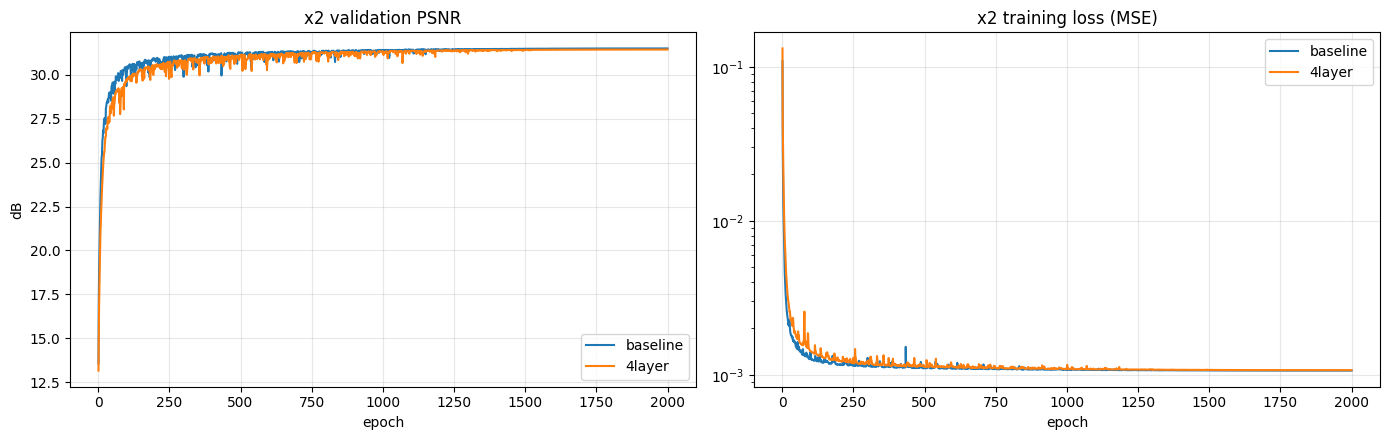

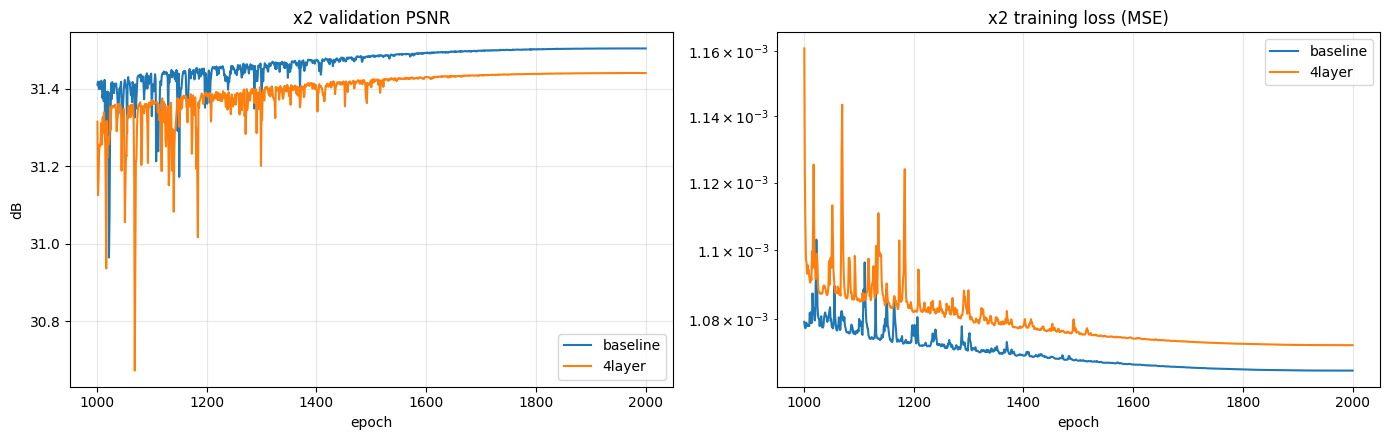

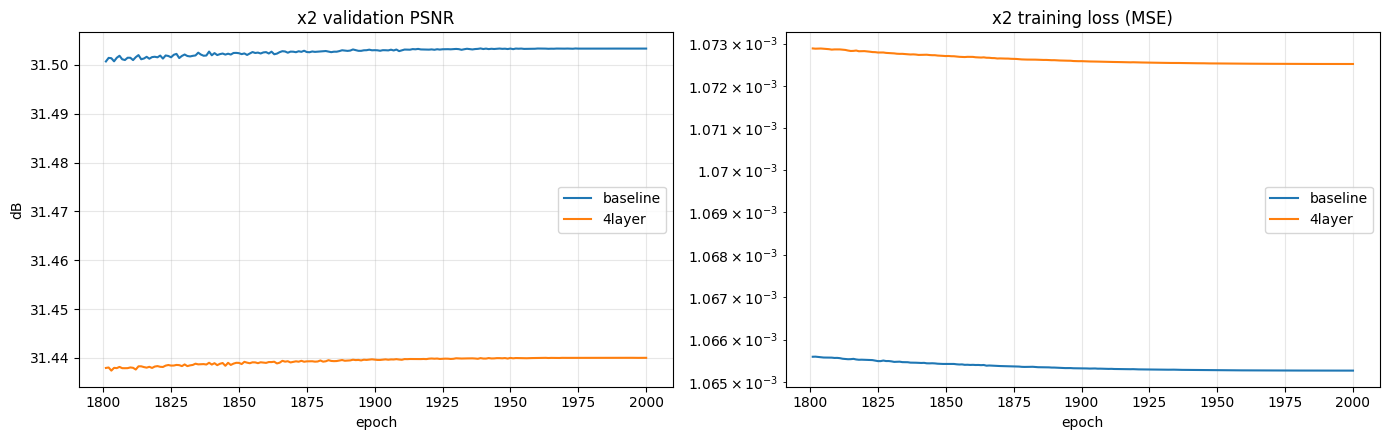

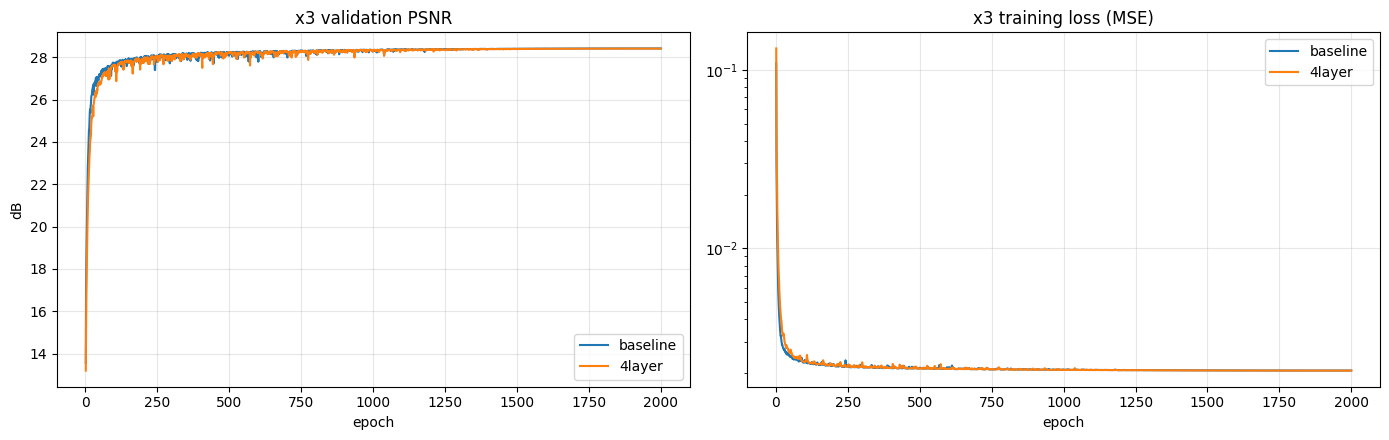

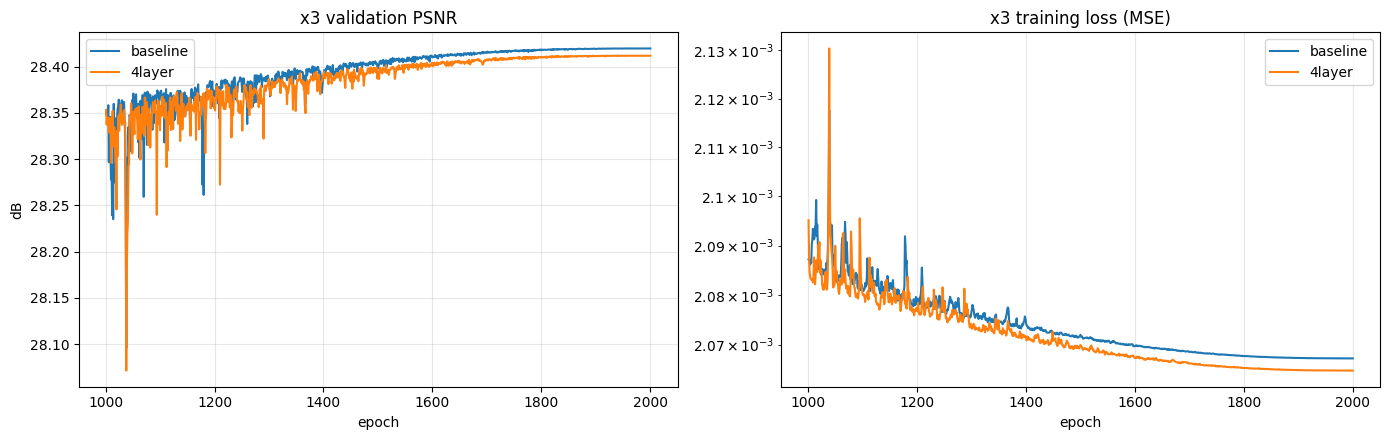

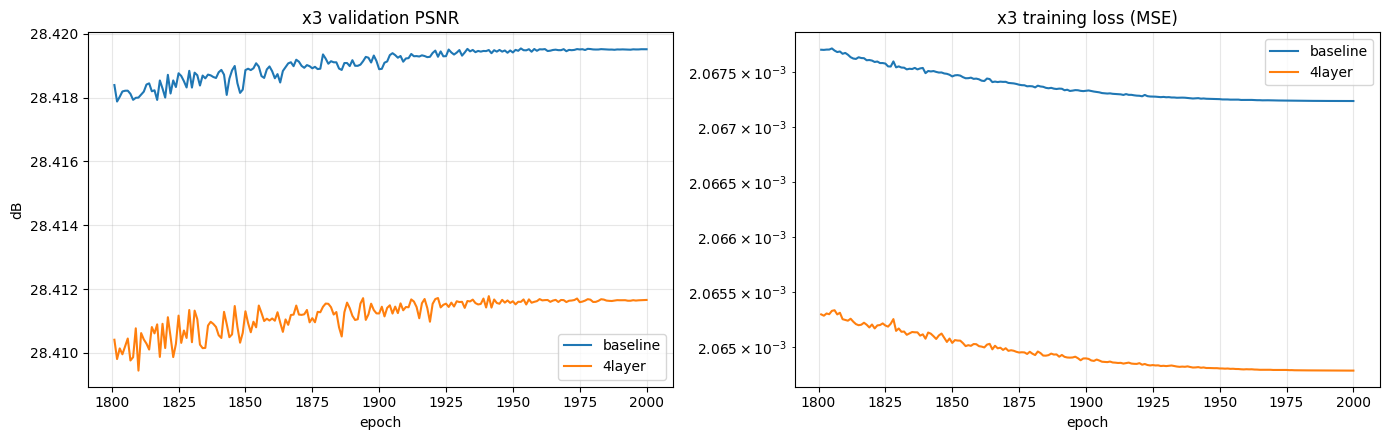

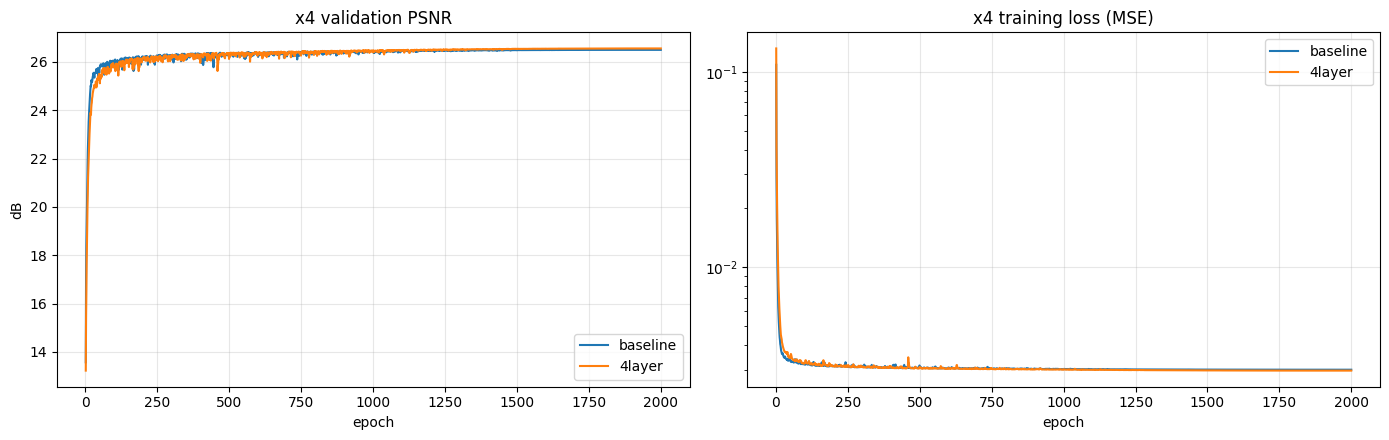

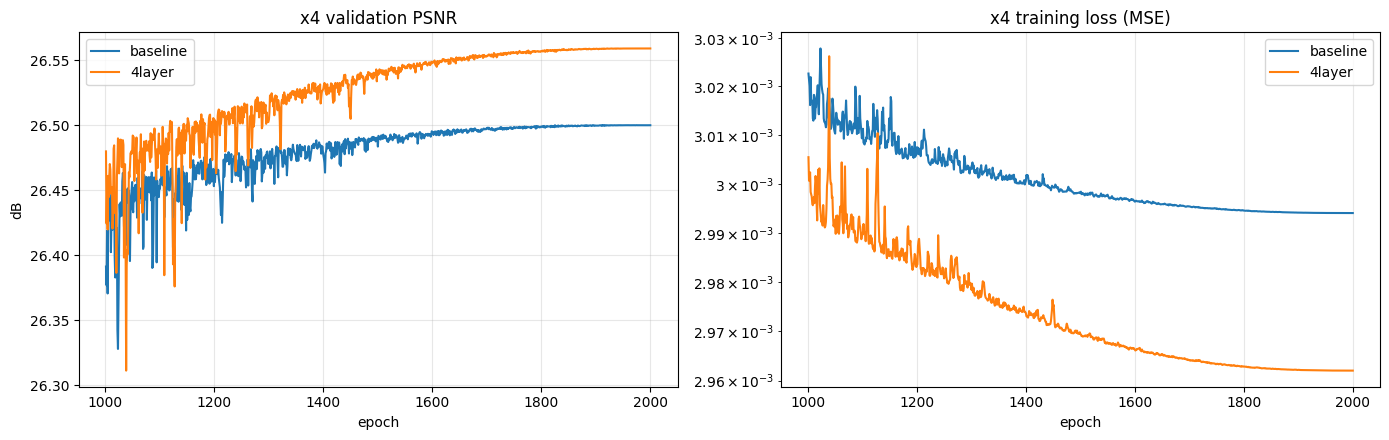

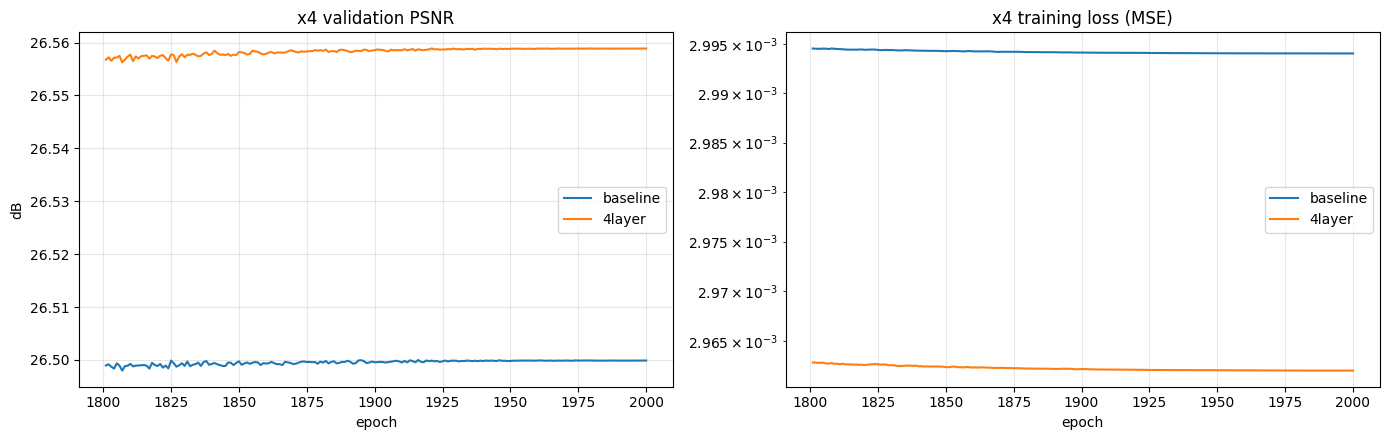

In [9]:
def plot_curves(scale, p):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for name in MODELS:
        hs = [pd.read_csv(f) for f in sorted(glob.glob(os.path.join(run_dir(scale, "*"), f"{name}_history.csv")))]
        if not hs:
            continue
        mean = pd.concat(hs).groupby("epoch").mean()
        mean = mean[int(e*p):]
        axes[0].plot(mean.index, mean["val_psnr"], label=name)
        axes[1].plot(mean.index, mean["train_loss"], label=name)
    axes[0].set(title=f"x{scale} validation PSNR", xlabel="epoch", ylabel="dB")
    axes[1].set(title=f"x{scale} training loss (MSE)", xlabel="epoch", yscale="log")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

for s in SCALES:
    plot_curves(s, 0)
    plot_curves(s, 0.5)
    plot_curves(s, 0.9)
    

In [10]:
SHAVE = None

def psnr_y(a, b, shave):
    if shave > 0:
        a, b = a[..., shave:-shave, shave:-shave], b[..., shave:-shave, shave:-shave]
    mse = ((a - b) ** 2).mean().clamp_min(1e-10)
    return (10 * torch.log10(1.0 / mse)).item()

def load_test_pairs(folder, scale):
    """Whole images: (bicubic-upscaled LR, HR), Y channel, [1,1,H,W] in 0..1."""
    pairs = []
    for f in list_images(folder):
        y = np.array(Image.open(f).convert("YCbCr").split()[0])
        H, W = y.shape[0] // scale * scale, y.shape[1] // scale * scale
        hr = y[:H, :W]
        lr = np.array(Image.fromarray(hr).resize((W // scale, H // scale), Image.BICUBIC).resize((W, H), Image.BICUBIC))
        t = lambda a: torch.from_numpy(a).float().div(255)[None, None]
        pairs.append((t(lr), t(hr)))
    return pairs

@torch.no_grad()
def evaluate_test():
    """For every (set, scale, seed, model): reconstruct EVERY image of the set, PSNR per image,
    average over the images of the set. Averaging over seeds is done afterwards in the table."""
    rows = []
    for set_name, folder in TEST_SETS.items():
        for scale in SCALES:
            shave = scale if SHAVE is None else SHAVE
            pairs = [(lr.to(DEVICE), hr.to(DEVICE)) for lr, hr in load_test_pairs(folder, scale)]
            rows.append({"set": set_name, "scale": scale, "seed": 0, "model": "bicubic", "n_images": len(pairs),
                         "psnr": np.mean([psnr_y(lr, hr, shave) for lr, hr in pairs])})
            for seed in SEEDS:
                for name in MODELS:
                    path = os.path.join(run_dir(scale, seed), f"{name}_best.pth")
                    if not os.path.exists(path):
                        continue
                    model = build_model(name).to(DEVICE)
                    model.load_state_dict(torch.load(path, map_location=DEVICE))
                    model.eval()
                    ps = [psnr_y(model(lr).clamp(0, 1), hr, shave) for lr, hr in pairs]
                    rows.append({"set": set_name, "scale": scale, "seed": seed, "model": name,
                                 "n_images": len(pairs), "psnr": np.mean(ps)})
    return pd.DataFrame(rows)

test_df = evaluate_test()
test_df.to_csv(os.path.join(OUT_DIR, "test_results.csv"), index=False)

def make_table(set_name):
    d = test_df[test_df["set"] == set_name]
    nets = d[d.model != "bicubic"]
    per_seed = nets.pivot_table(index=["scale", "model"], columns="seed", values="psnr", sort=False)
    per_seed.columns = [f"seed {s}" for s in per_seed.columns]
    seed_cols = list(per_seed.columns)
    bic = d[d.model == "bicubic"].set_index(["scale", "model"])["psnr"]
    table = pd.concat([pd.DataFrame({c: bic for c in seed_cols}), per_seed])
    table["Mean"] = table[seed_cols].mean(axis=1)      # mean over seeds
    table["± std"] = table[seed_cols].std(axis=1)
    return table.sort_index(level=0, sort_remaining=False)

for set_name in TEST_SETS:
    n = int(test_df[test_df["set"] == set_name]["n_images"].iloc[0])
    display(pretty(make_table(set_name), f"{set_name} PSNR (Y, {n} full images per model/seed, then mean over seeds)").format("{:.3f}")
            .highlight_max(subset=["Mean"], props="background-color: #d6f5d6; font-weight: bold;"))
